
# Pooya Valizadeh

**GitHub:** [PooyaValizadeh](https://github.com/PooyaValizadeh)  
**Kaggle:** [PooyaValizadeh](https://www.kaggle.com/PooyaValizadeh)

---

In [10]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:
def f(a, b):
    return (a**2 + b - 11)**2 + (2*a + b**2 - 7)**2

def g(a, b):
    da = 4*a*(a**2 + b - 11) + 4*(2*a + b**2 - 7)
    db = 2*(a**2 + b - 11) + 4*b*(2*a + b**2 - 7)
    return da, db

In [12]:
class Opt:
    def __init__(self, lr):
        self.lr = lr

    def gd(self, a, b, v1, v2):
        da, db = g(a, b)
        return a - self.lr * da, b - self.lr * db, 0, 0

    def mom(self, a, b, v1, v2):
        da, db = g(a, b)
        v1 = 0.9 * v1 - self.lr * da
        v2 = 0.9 * v2 - self.lr * db
        return a + v1, b + v2, v1, v2

    def nest(self, a, b, v1, v2):
        a2 = a + 0.9 * v1
        b2 = b + 0.9 * v2
        da, db = g(a2, b2)
        v1 = 0.9 * v1 - self.lr * da
        v2 = 0.9 * v2 - self.lr * db
        return a + v1, b + v2, v1, v2

    def adag(self, a, b, r1, r2):
        da, db = g(a, b)
        r1 = r1 + da**2
        r2 = r2 + db**2
        a = a - self.lr / (1e-7 + np.sqrt(r1)) * da
        b = b - self.lr / (1e-7 + np.sqrt(r2)) * db
        return a, b, r1, r2

    def rms(self, a, b, r1, r2):
        da, db = g(a, b)
        r1 = 0.9 * r1 + 0.1 * da**2
        r2 = 0.9 * r2 + 0.1 * db**2
        a = a - self.lr / np.sqrt(1e-7 + r1) * da
        b = b - self.lr / np.sqrt(1e-7 + r2) * db
        return a, b, r1, r2

    def adam(self, a, b, s1, s2, r1, r2, t):
        da, db = g(a, b)
        s1 = 0.9 * s1 + 0.1 * da
        s2 = 0.9 * s2 + 0.1 * db
        r1 = 0.999 * r1 + 0.001 * da**2
        r2 = 0.999 * r2 + 0.001 * db**2
        s1h = s1 / (1 - 0.9**(t+1))
        s2h = s2 / (1 - 0.9**(t+1))
        r1h = r1 / (1 - 0.999**(t+1))
        r2h = r2 / (1 - 0.999**(t+1))
        a = a - self.lr * s1h / (np.sqrt(r1h) + 1e-8)
        b = b - self.lr * s2h / (np.sqrt(r2h) + 1e-8)
        return a, b, s1, s2, r1, r2

In [13]:
def run_gd(fn, st, n=10):
    a, b = st
    v1 = v2 = 0
    p = [(a, b)]
    for i in range(n):
        a, b, v1, v2 = fn(a, b, v1, v2)
        p.append((a, b))
    return p

def run_ad(fn, st, n=10):
    a, b = st
    r1 = r2 = 0
    p = [(a, b)]
    for i in range(n):
        a, b, r1, r2 = fn(a, b, r1, r2)
        p.append((a, b))
    return p

def run_adam(fn, st, n=10):
    a, b = st
    s1 = s2 = r1 = r2 = 0
    p = [(a, b)]
    for t in range(n):
        a, b, s1, s2, r1, r2 = fn(a, b, s1, s2, r1, r2, t)
        p.append((a, b))
    return p

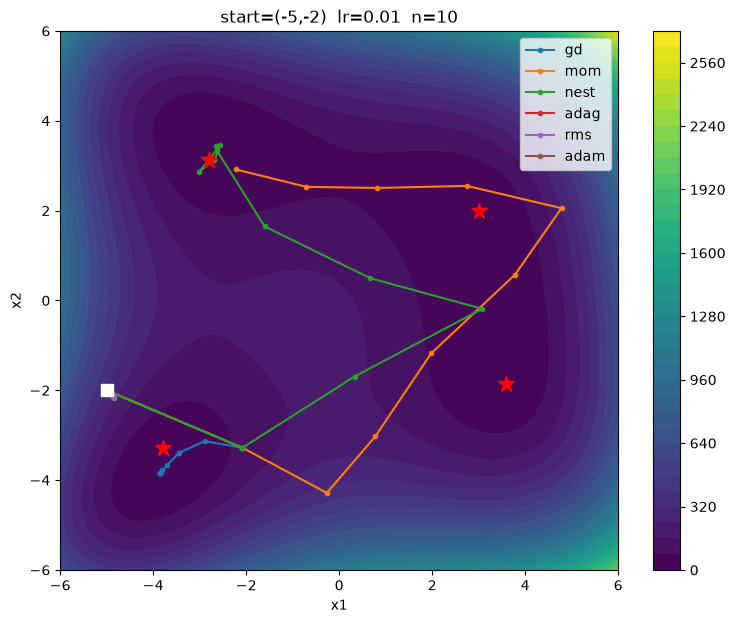

In [14]:
o = Opt(0.01)
st = (-5, -2)

p1 = run_gd(o.gd, st)
p2 = run_gd(o.mom, st)
p3 = run_gd(o.nest, st)
p4 = run_ad(o.adag, st)
p5 = run_ad(o.rms, st)
p6 = run_adam(o.adam, st)

xx = np.linspace(-6, 6, 300)
yy = np.linspace(-6, 6, 300)
X, Y = np.meshgrid(xx, yy)
Z = f(X, Y)

mins = [(3,2), (-2.8,3.13), (-3.78,-3.28), (3.58,-1.85)]

plt.figure(figsize=(9,7))
plt.contourf(X, Y, Z, 40, cmap='viridis')
plt.colorbar()
for name, p in [('gd',p1),('mom',p2),('nest',p3),('adag',p4),('rms',p5),('adam',p6)]:
    xs, ys = zip(*p)
    plt.plot(xs, ys, '-o', ms=3, label=name)
plt.plot(*zip(*mins), 'r*', ms=12)
plt.plot(st[0], st[1], 'ws', ms=8)
plt.legend()
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('start=(-5,-2)  lr=0.01  n=10')
plt.xlim(-6,6)
plt.ylim(-6,6)
plt.savefig('same_start.png', dpi=120)
plt.show()


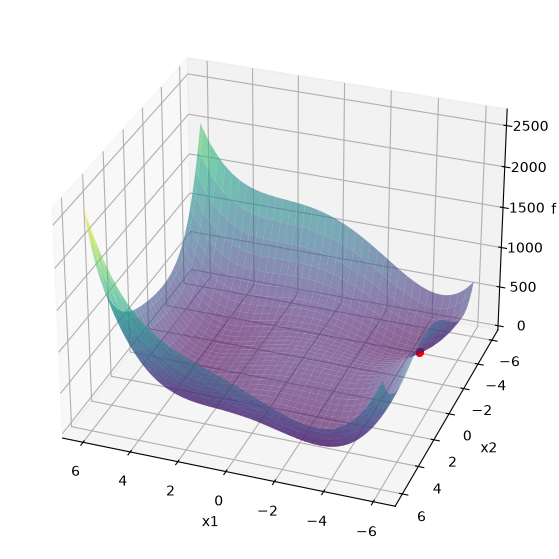

In [15]:
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.6, rstride=8, cstride=8)
xs, ys = zip(*p6)
zs = [f(x,y) for x,y in p6]
ax.plot(xs, ys, zs, 'r-o', ms=4)
ax.view_init(30, 110)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('f')
plt.show()